In [1]:
import numpy as np
import sklearn 
import matplotlib.pyplot as plt

In [2]:
from sklearn import linear_model
from sklearn.model_selection import train_test_split

# Task1

In [3]:
def ols(x_train,y):
    N,d=np.shape(x_train)
    x_t=np.c_[np.ones((N,1)),x_train]
    reg=linear_model.LinearRegression()
    reg.fit(x_t,y,)
    return reg.coef_

In [4]:
def standardise(x_t):
    means=x_t.mean(axis=0)
    std=x_t.std(axis=0)
    std_x_t=(x_t-means)/std
    return std_x_t

In [5]:
set=np.loadtxt("air_quality_data.csv",skiprows=1,delimiter=',')
X_train, X_test, y_train, y_test=train_test_split(set[:,:-1],set[:,-1],train_size=0.999,random_state=42)
std_X_train=standardise(X_train)
print("raw:")
print(ols(X_train,y_train))
print("\nstandardised:")
print(ols(std_X_train,y_train))


raw:
[ 0.00000000e+00  1.09873766e-01  2.21194661e+01 -1.17887500e-01
 -3.38191451e-02 -2.09291438e-01  1.04830887e-02  4.44031680e-02
 -5.61944011e-02]

standardised:
[ 0.          4.34174307 12.47122018 -2.94915826 -0.85155498 -0.551431
  0.12197729  0.85837411 -0.15421503]


# Task2

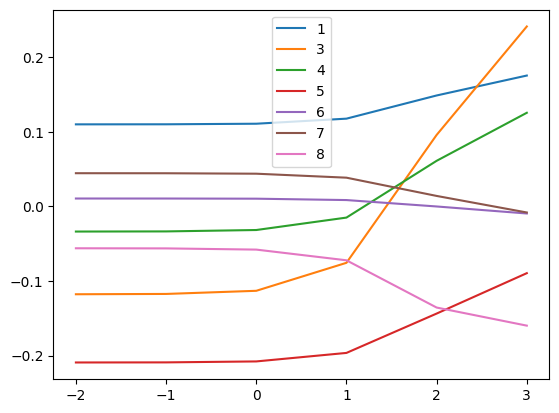

In [6]:
coeff=[]
for lambdaa in [0.01, 0.1, 1, 10, 100, 1000]:
    clf=linear_model.Ridge(alpha=lambdaa)
    clf.fit(X_train,y_train)
    coeff.append(clf.coef_)

coefs=np.array(coeff)

plt.figure()
for i in [0,2,3,4,5,6,7]:
    plt.plot([-2,-1,0,1,2,3],coefs[:,i],label=i+1)
plt.legend()
plt.show()


# Task3

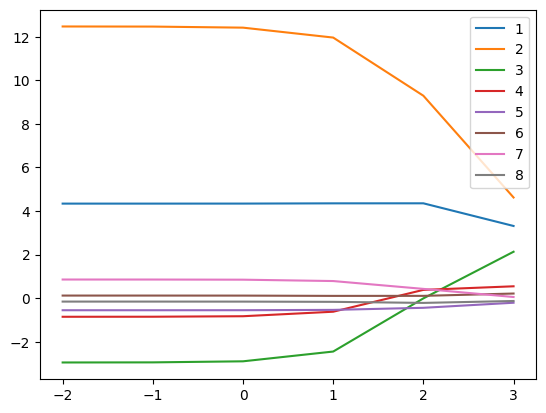

In [7]:
sca=sklearn.preprocessing.StandardScaler()
sca.fit(X_train)
std_X_train=sca.transform(X_train)
coeff=[]
for lambdaa in [0.01, 0.1, 1, 10, 100, 1000]:
    clf=linear_model.Ridge(alpha=lambdaa)
    clf.fit(std_X_train,y_train)
    coeff.append(clf.coef_)

coefs=np.array(coeff)

plt.figure()
for i in [0,1,2,3,4,5,6,7]:
    plt.plot([-2,-1,0,1,2,3],coefs[:,i],label=i+1)
plt.legend()
plt.show()


# Task4

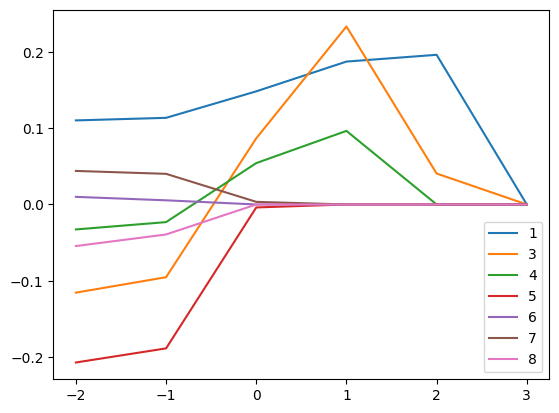

In [8]:
coeff=[]
for lambdaa in [0.01, 0.1, 1, 10, 100, 1000]:
    clf=linear_model.Lasso(alpha=lambdaa)
    clf.fit(X_train,y_train)
    coef=clf.coef_
    coeff.append(coef)

coefs=np.array(coeff)

plt.figure()
for i in [0,2,3,4,5,6,7]:
    plt.plot([-2,-1,0,1,2,3],coefs[:,i],label=i+1)
plt.legend()
plt.show()

# Task5

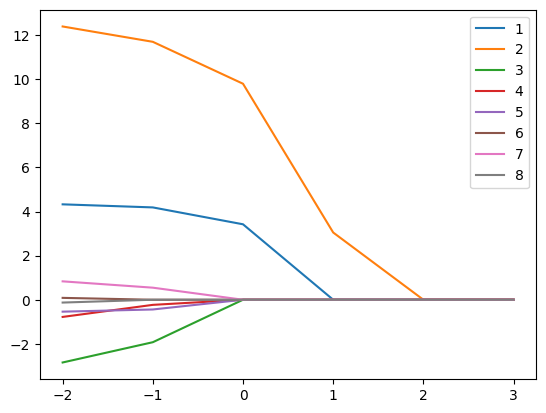

In [9]:
coeff=[]
for lambdaa in [0.01, 0.1, 1, 10, 100, 1000]:
    clf=linear_model.Lasso(alpha=lambdaa)
    clf.fit(std_X_train,y_train)
    coef=clf.coef_
    coeff.append(coef)

coefs=np.array(coeff)

plt.figure()
for i in [0,1,2,3,4,5,6,7]:
    plt.plot([-2,-1,0,1,2,3],coefs[:,i],label=i+1)
plt.legend()
plt.show()

# Task6

In [10]:
x_a = X_train[X_train[:, 0]>200]
x_b = X_train[X_train[:, 1] > 4]
x_c = X_train[(X_train[:, 0]>200) & (X_train[:, 1]>4)]
print(x_a.shape, x_b.shape, x_c.shape)

(14, 8) (9, 8) (7, 8)


In [11]:
X_outliers_removed = X_train[(X_train[:, 0]<200) & (X_train[:, 1]<4)]
y_outliers_removed = y_train[(X_train[:, 0]<200) & (X_train[:, 1]<4)]
sca=sklearn.preprocessing.RobustScaler()
sca.fit(X_train)
median_std_X_train=sca.transform(X_train)

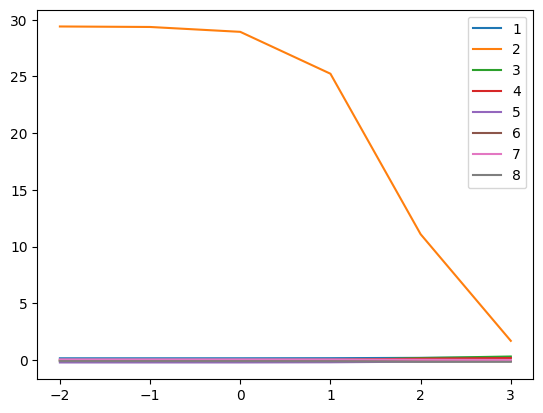

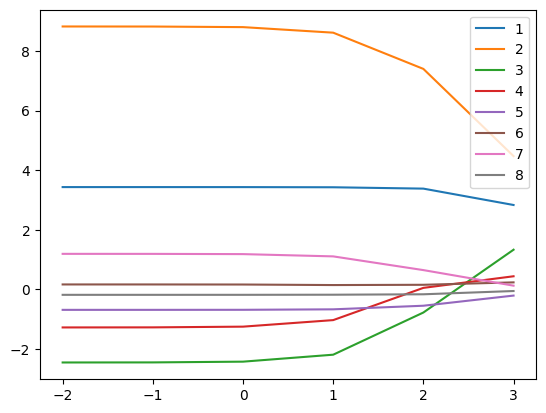

In [14]:
coeff1=[]
coeff2=[]
for lambdaa in [0.01, 0.1, 1, 10, 100, 1000]:
    clf1=linear_model.Ridge(alpha=lambdaa)
    clf1.fit(X_outliers_removed,y_outliers_removed)
    coeff1.append(clf1.coef_)
    clf2=linear_model.Ridge(alpha=lambdaa)
    clf2.fit(median_std_X_train,y_train)
    coeff2.append(clf2.coef_)

coefs1=np.array(coeff1)
coefs2=np.array(coeff2)

plt.figure()
for i in [0,2,3,4,5,6,7]:
    plt.plot([-2,-1,0,1,2,3],coefs1[:,i],label=i+1)
plt.legend()
plt.show() 

plt.figure()
for i in [0,1,2,3,4,5,6,7]:
    plt.plot([-2,-1,0,1,2,3],coefs2[:,i],label=i+1)
plt.legend()
plt.show() 